In [2]:
from sklearn.datasets import load_iris
iris = load_iris()

In [4]:
import pandas as pd
X = pd.DataFrame(iris.data, columns=iris.feature_names)
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [5]:
y = pd.Series(iris.target)
print(y.value_counts())

0    50
1    50
2    50
Name: count, dtype: int64


In [7]:
# make a copy of X and y and make a new dataframe with values for the target y
df = X.copy()
df['target'] = y
df.head() # we can see the new colum target is added to the features

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Text(0, 0.5, 'Count')

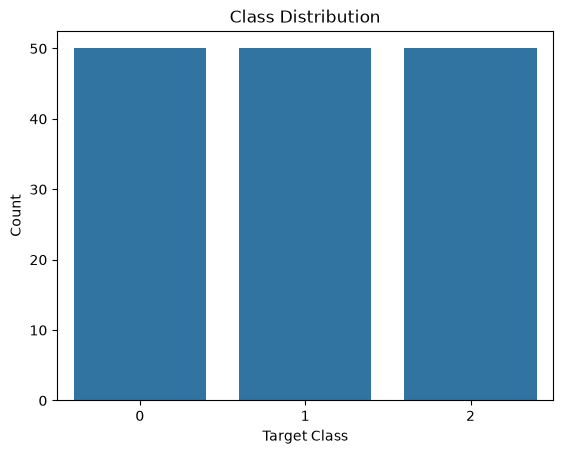

In [9]:
## Visualizing dataset strucuture before going to machine learning model
# class distribution
# we will use seaborn library to visualize the data
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=iris.target) # we can see each index has 50 values (50 image data)
# add the chart components
plt.title("Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Count")


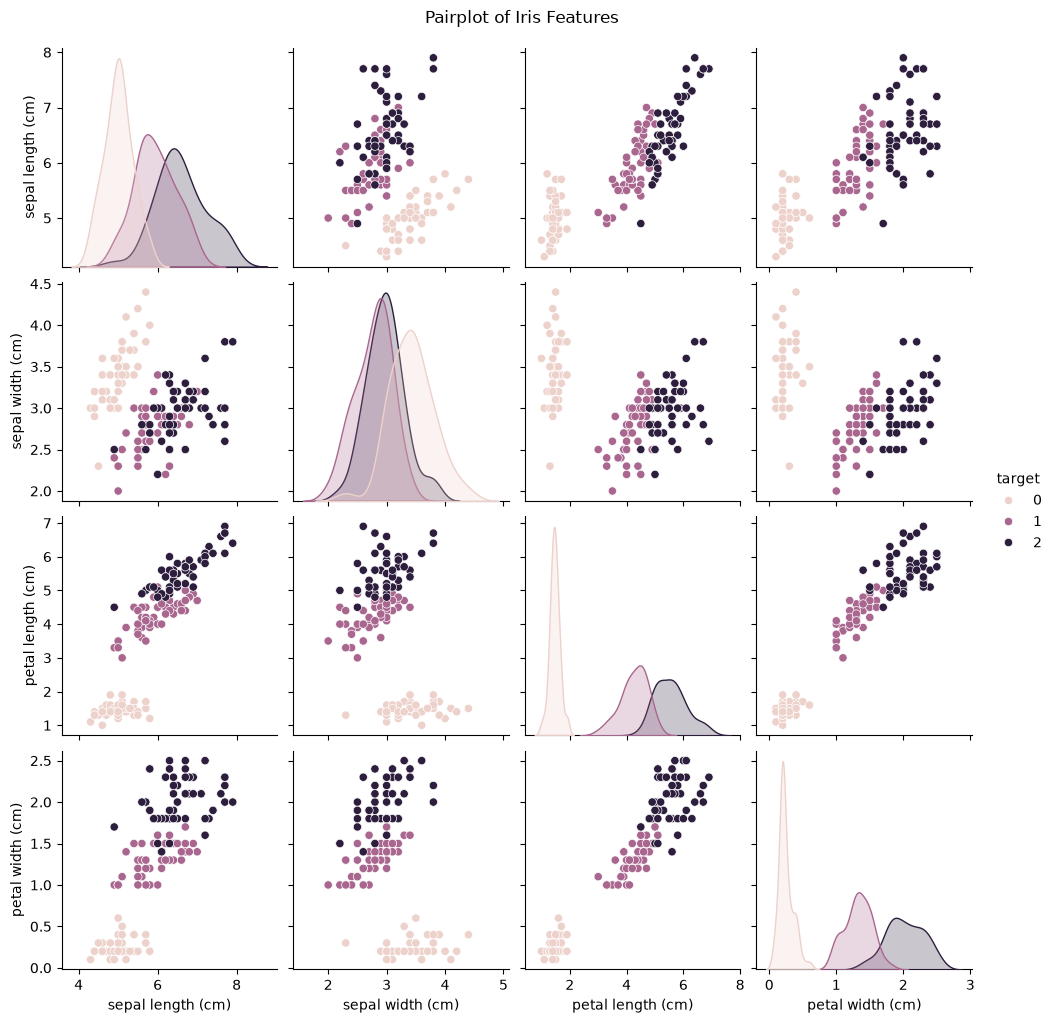

In [10]:
# draw a pairplot
sns.pairplot(df, hue='target')
plt.suptitle('Pairplot of Iris Features', y=1.02)
plt.show()

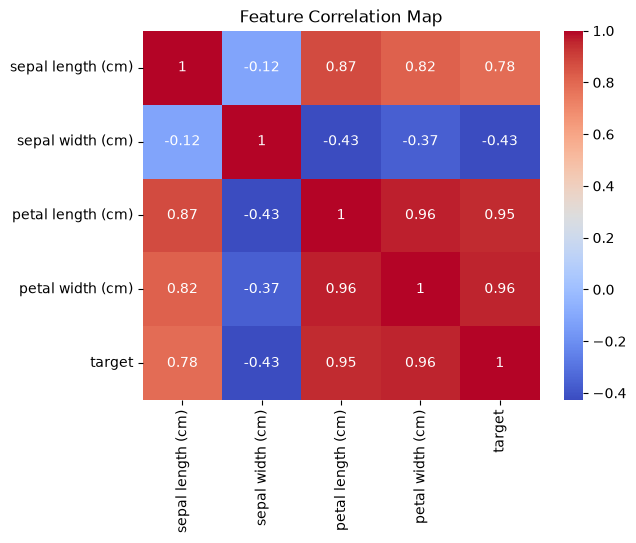

In [11]:
# plot a correlation map
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Feature Correlation Map')
plt.show()

In [12]:
# split the data for training and testing
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
# standardization using the scaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

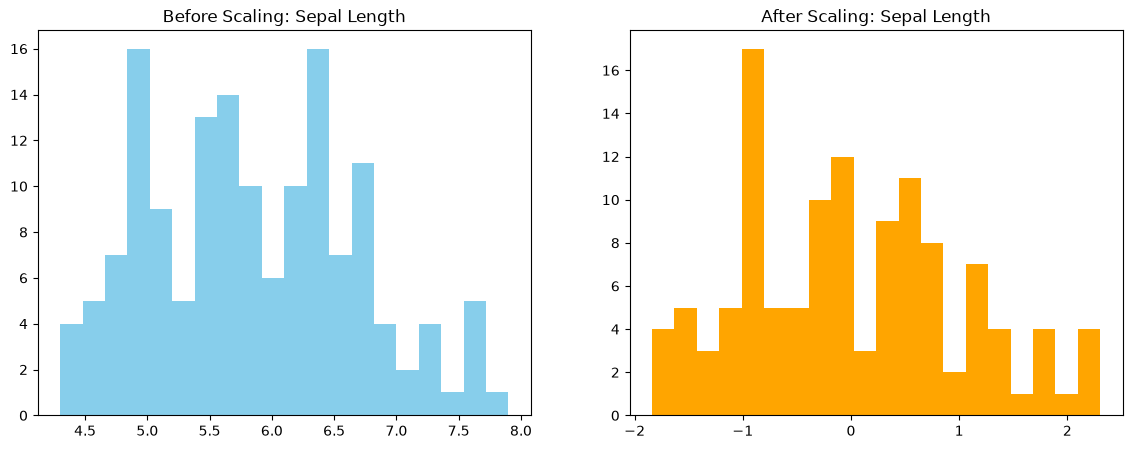

In [18]:
# visualizae the dataset before and after scaling
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,2, figsize=(14,5))

ax[0].hist(X.iloc[:, 0], bins=20, color='skyblue')
ax[0].set_title('Before Scaling: Sepal Length')

ax[1].hist(X_train[:, 0], bins=20, color='orange')
ax[1].set_title('After Scaling: Sepal Length')

plt.show()

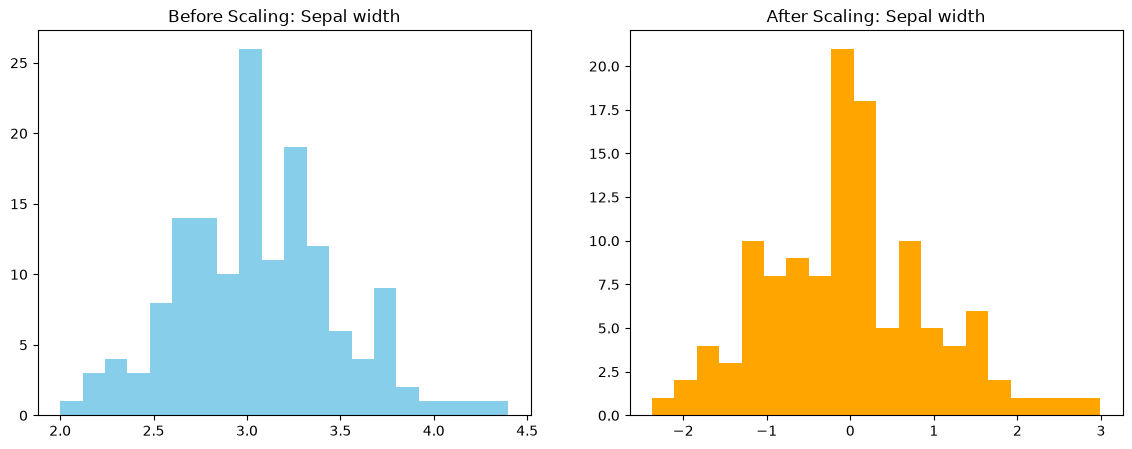

In [19]:
# same for sepal width
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,2, figsize=(14,5))

ax[0].hist(X.iloc[:, 1], bins=20, color='skyblue')
ax[0].set_title('Before Scaling: Sepal width')

ax[1].hist(X_train[:, 1], bins=20, color='orange')
ax[1].set_title('After Scaling: Sepal width')

plt.show()

In [ ]:
# implementing KNN using sklearn
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3) # because we have 3 types of flowers to predict in the data set
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)


In [21]:
type(y_pred_knn)

numpy.ndarray

In [22]:
y_pred_knn

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0])

In [23]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

In [24]:
type(y_pred_tree)

numpy.ndarray

In [25]:
y_pred_tree

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0])

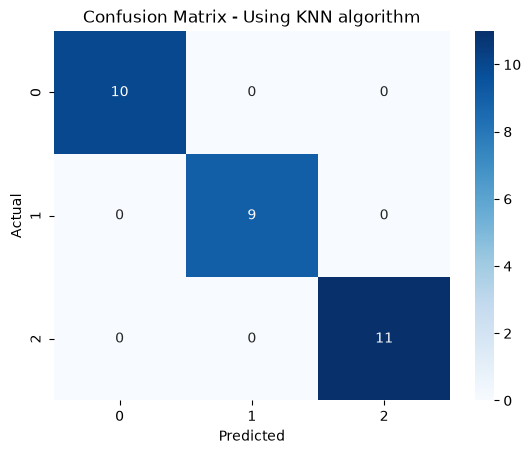

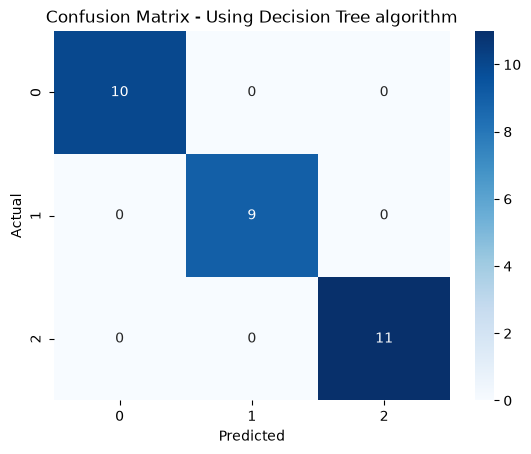

In [26]:
# Evaluating the model output using confusion matrix

from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()

plot_confusion(y_test, y_pred_knn, "Confusion Matrix - Using KNN algorithm")
plot_confusion(y_test, y_pred_tree, "Confusion Matrix - Using Decision Tree algorithm")

In [27]:
# create a classification report
print('KNN Report: ', classification_report(y_test, y_pred_knn))
print('Tree Report: ', classification_report(y_test, y_pred_tree))

KNN Report:                precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Tree Report:                precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

